# DIA-NN version comparison vs Spectronaut (five-way)

> **Informative**, but not included in manuscript.

Five datasets, all on the same samples:

| Dataset | Level available | Labs |
|---|---|---|
| DIA-NN 2.2 (1st pass) | precursor only | all |
| DIA-NN 2.2 (2nd pass) | precursor + protein | all |
| DIA-NN 2.6 (1st pass) | precursor only | all |
| DIA-NN 2.6 (2nd pass) | precursor + protein | all |
| Spectronaut | precursor + protein | all |

First-pass DIA-NN runs have no protein inference (the protein matrices are all zero), so
those two datasets are used at the **precursor level only**.

Two analyses:
- **Part A** — improvement from DIA-NN 2.2 to 2.6 (within-tool, same MaxLFQ units).
- **Part B** — DIA-NN 2.6 vs Spectronaut, with emphasis on a lab-by-lab breakdown.
- **Part C** — completeness and reproducibility, lab-by-lab.


## 1. Imports & load data


In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import anndata as ad
from scipy.stats import pearsonr

from SCI_py.constants.plotting import LAB_COLORS, LAB_ORDER, CONDITION_COLORS
from SCI_py.metrics.completeness import compute_completeness
from SCI_py.metrics.cvs import compute_cv_matrix
from SCI_py.plot.version_comparison import (
    shared_obs,
    compute_overlap_decomposition,
    compute_binned_overlap,
    plot_id_counts_overview,
    plot_id_counts_per_lab,
    plot_protein_counts,
    plot_version_improvement,
    plot_feature_overlap,
    plot_quantitative_correlation,
    plot_tool_counts_per_lab,
    plot_tool_overlap,
    plot_paired_per_lab,
    plot_overlap_decomposition_per_lab,
    plot_overlap_overview,
    plot_binned_overlap_boxplot,
    plot_binned_overlap_profile,
    plot_completeness_multi_dataset,
    plot_cv_multi_dataset,
)

In [2]:
# ── Paths ────────────────────────────────────────────────────────────────────
DIANN22_1stpass = '/home/sam/SCI/SCI/Data/AnnData/DIANN/v2.2/first_pass/base'
DIANN22_2ndpass = '/home/sam/SCI/SCI/Data/AnnData/DIANN/v2.2/second_pass/base'
DIANN26_1stpass = '/home/sam/SCI/SCI/Data/AnnData/DIANN/v2.6/first_pass/base'
DIANN26_2ndpass = '/home/sam/SCI/SCI/Data/AnnData/DIANN/v2.6/second_pass/base'
SPECTRONAUT_DIR = '/home/sam/SCI/SCI/Data/AnnData/Spectronaut/base'

# ── Set SAVE_DIR to a directory path to save all figures, or None to skip ────
SAVE_DIR = "/home/sam/SCI/SCI/Figures/software_comparison"

DATASET_ORDER = [
    'DIA-NN 2.2 (1st pass)',
    'DIA-NN 2.2 (2nd pass)',
    'DIA-NN 2.6 (1st pass)',
    'DIA-NN 2.6 (2nd pass)',
    'Spectronaut',
]
DATASET_COLORS = {
    'DIA-NN 2.2 (1st pass)': '#A6C8E0',
    'DIA-NN 2.2 (2nd pass)': '#1F6FB2',
    'DIA-NN 2.6 (1st pass)': '#A6DDB0',
    'DIA-NN 2.6 (2nd pass)': '#2C9E4B',
    'Spectronaut'          : '#C44E52',
}

# Datasets with real protein inference (1st-pass protein matrices are empty).
PROTEIN_DATASETS = [
    'DIA-NN 2.2 (2nd pass)',
    'DIA-NN 2.6 (2nd pass)',
    'Spectronaut',
]

_paths = {
    'DIA-NN 2.2 (1st pass)': DIANN22_1stpass,
    'DIA-NN 2.2 (2nd pass)': DIANN22_2ndpass,
    'DIA-NN 2.6 (1st pass)': DIANN26_1stpass,
    'DIA-NN 2.6 (2nd pass)': DIANN26_2ndpass,
    'Spectronaut'          : SPECTRONAUT_DIR,
}

# Precursor objects for all five; protein objects only where inference was done.
prec = {name: ad.read_h5ad(os.path.join(p, 'adata_precursor.h5ad'))
        for name, p in _paths.items()}
prot = {name: ad.read_h5ad(os.path.join(_paths[name], 'adata_protein.h5ad'))
        for name in PROTEIN_DATASETS}

print('Loaded:')
for name in DATASET_ORDER:
    has_prot = 'prec + prot' if name in prot else 'prec only'
    print(f'  {name:24s}  prec {prec[name].shape}  [{has_prot}]')

Loaded:
  DIA-NN 2.2 (1st pass)     prec (2546, 69206)  [prec only]
  DIA-NN 2.2 (2nd pass)     prec (2617, 61428)  [prec + prot]
  DIA-NN 2.6 (1st pass)     prec (2562, 112747)  [prec only]
  DIA-NN 2.6 (2nd pass)     prec (2672, 87495)  [prec + prot]
  Spectronaut               prec (3114, 72061)  [prec + prot]


## 2. Scope, helpers & overview

Helper functions and the comparison scope are defined here.

Identifications are counted on the **linear** `.X` matrix (`value > 0` = detected), which is
robust to whether missing values are stored as `NaN` or `0`. Quantitative correlations use the
`X_log2` layer (`NaN` = missing).

The set of labs for which DIA-NN 2.6 data exist is discovered automatically and stored in
`LABS_26`. All comparisons that involve 2.6 are restricted to those labs.


In [3]:
SC_CONDITIONS = ['K562', 'HEK293T']
QC_CONDITIONS = ['QC - Hela']


def _lab_order(labs):
    return [l for l in LAB_ORDER if l in labs] + [l for l in labs if l not in LAB_ORDER]


print('Helpers defined.')

Helpers defined.


In [4]:
# ── Discover the labs covered by DIA-NN 2.6 (partial view) ───────────────────
LABS_26 = sorted(set(prec['DIA-NN 2.6 (1st pass)'].obs['plate_idx'])
                 & set(prec['DIA-NN 2.6 (2nd pass)'].obs['plate_idx']))
LABS_26_ORDER = _lab_order(LABS_26)
LABS_ALL      = _lab_order(sorted(prec['DIA-NN 2.2 (2nd pass)'].obs['plate_idx'].unique()))

print(f'Labs with DIA-NN 2.6 data ({len(LABS_26)}): {LABS_26}')
print(f'All labs (DIA-NN 2.2)     ({len(LABS_ALL)}): {LABS_ALL}')
print()

# ── Overview table ───────────────────────────────────────────────────────────
rows = []
for name in DATASET_ORDER:
    a = prec[name]
    rows.append({
        'Dataset'     : name,
        'Labs (n)'    : a.obs['plate_idx'].nunique(),
        'Samples'     : a.n_obs,
        'Precursors'  : a.n_vars,
        'Proteins'    : prot[name].n_vars if name in prot else 0,
        'Protein data': 'yes' if name in prot else 'no (1st pass)',
    })
summary_df = pd.DataFrame(rows).set_index('Dataset')
display(summary_df)

# ── Shared-sample bookkeeping for the comparisons ─────────────────────────────
SHARED_DIANN_26LABS = shared_obs(list(prec.values()), labs=LABS_26)
print(f'\nSamples present in all five datasets within 2.6 labs: {len(SHARED_DIANN_26LABS)}')


Labs with DIA-NN 2.6 data (9): ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']
All labs (DIA-NN 2.2)     (9): ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']



,Labs (n),Samples,Precursors,Proteins,Protein data
Dataset,,,,,
DIA-NN 2.2 (1st pass),9,2546,69206,0,no (1st pass)
DIA-NN 2.2 (2nd pass),9,2617,61428,6696,yes
DIA-NN 2.6 (1st pass),9,2562,112747,0,no (1st pass)
DIA-NN 2.6 (2nd pass),9,2672,87495,7121,yes
Spectronaut,9,3114,72061,7231,yes



Samples present in all five datasets within 2.6 labs: 2539


## Part A — DIA-NN 2.2 to 2.6 improvement

All panels are restricted to the labs that have DIA-NN 2.6 data (`LABS_26`), so 2.2 and 2.6
are compared on the same labs. Because both are DIA-NN MaxLFQ output, intensities and CVs are
on the same scale and are directly comparable here (unlike the cross-tool comparison in Part B).

- 1st pass: precursor level only.
- 2nd pass: precursor and protein level.


### A.1 Precursor identifications per sample (four DIA-NN datasets)


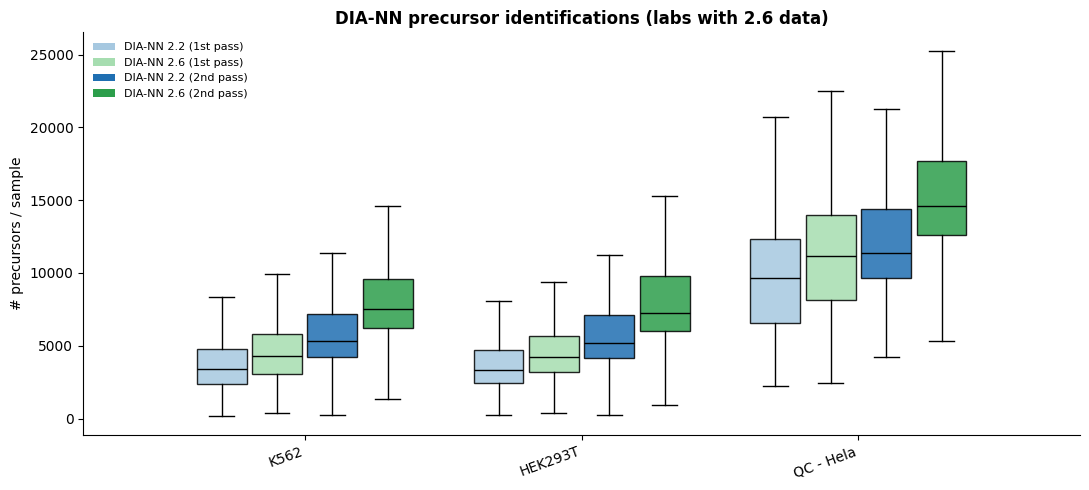

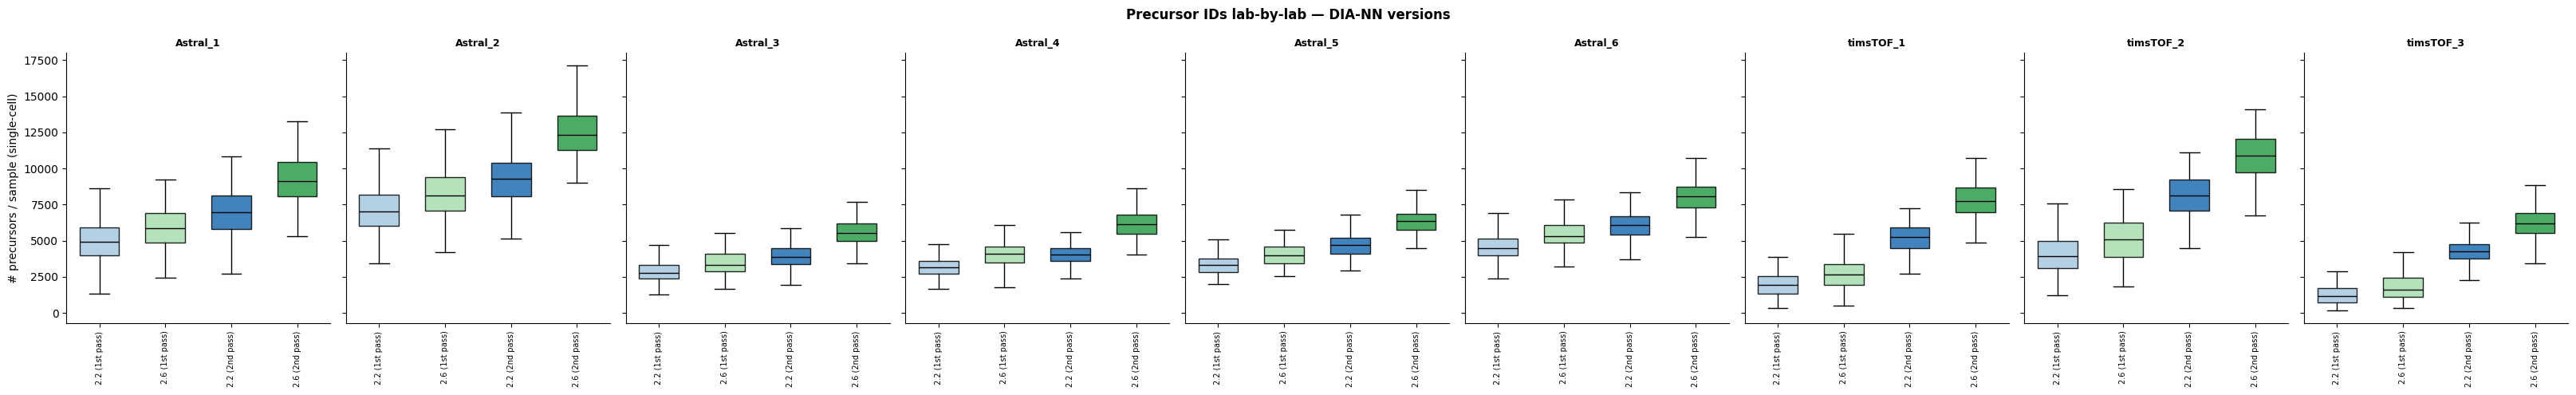

In [5]:
DIANN_PREC_ORDER = [
    'DIA-NN 2.2 (1st pass)', 'DIA-NN 2.6 (1st pass)',
    'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)',
]
conds = SC_CONDITIONS + QC_CONDITIONS

plot_id_counts_overview(
    prec, DIANN_PREC_ORDER, DATASET_COLORS,
    conditions=conds, labs=LABS_26,
    title='DIA-NN precursor identifications (labs with 2.6 data)',
    save_dir=SAVE_DIR,
)

plot_id_counts_per_lab(
    prec, DIANN_PREC_ORDER, DATASET_COLORS,
    lab_order=LABS_26_ORDER, labs=LABS_26, sc_conditions=SC_CONDITIONS,
    save_dir=SAVE_DIR,
)

### A.2 Protein identifications per sample (2nd pass only)


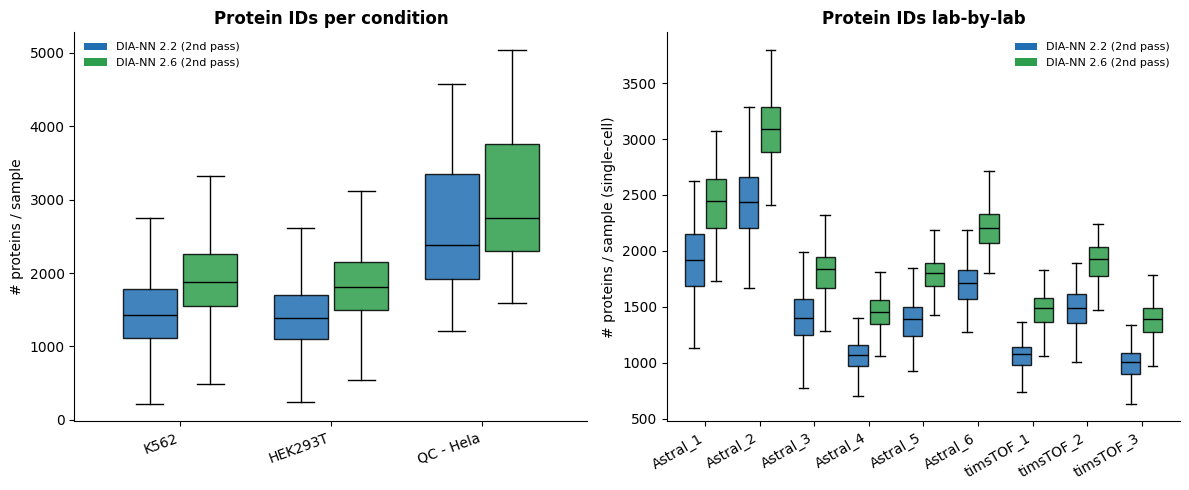

In [6]:
DIANN_PROT_ORDER = ['DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)']

plot_protein_counts(
    prot, DIANN_PROT_ORDER, DATASET_COLORS,
    lab_order=LABS_26_ORDER, labs=LABS_26,
    conditions=conds, sc_conditions=SC_CONDITIONS,
    save_dir=SAVE_DIR,
)

### A.3 Paired per-sample improvement (2.2 -> 2.6)

Each point is one sample, matched between versions. The diagonal marks no change; points above
it gained identifications in 2.6. The lower panels show the per-lab distribution of the gain
(`n_2.6 - n_2.2`).


Precursor 1st pass: median gain = +826  (n=1925 samples)
Precursor 2nd pass: median gain = +2127  (n=1929 samples)
Protein 2nd pass: median gain = +437  (n=1929 samples)


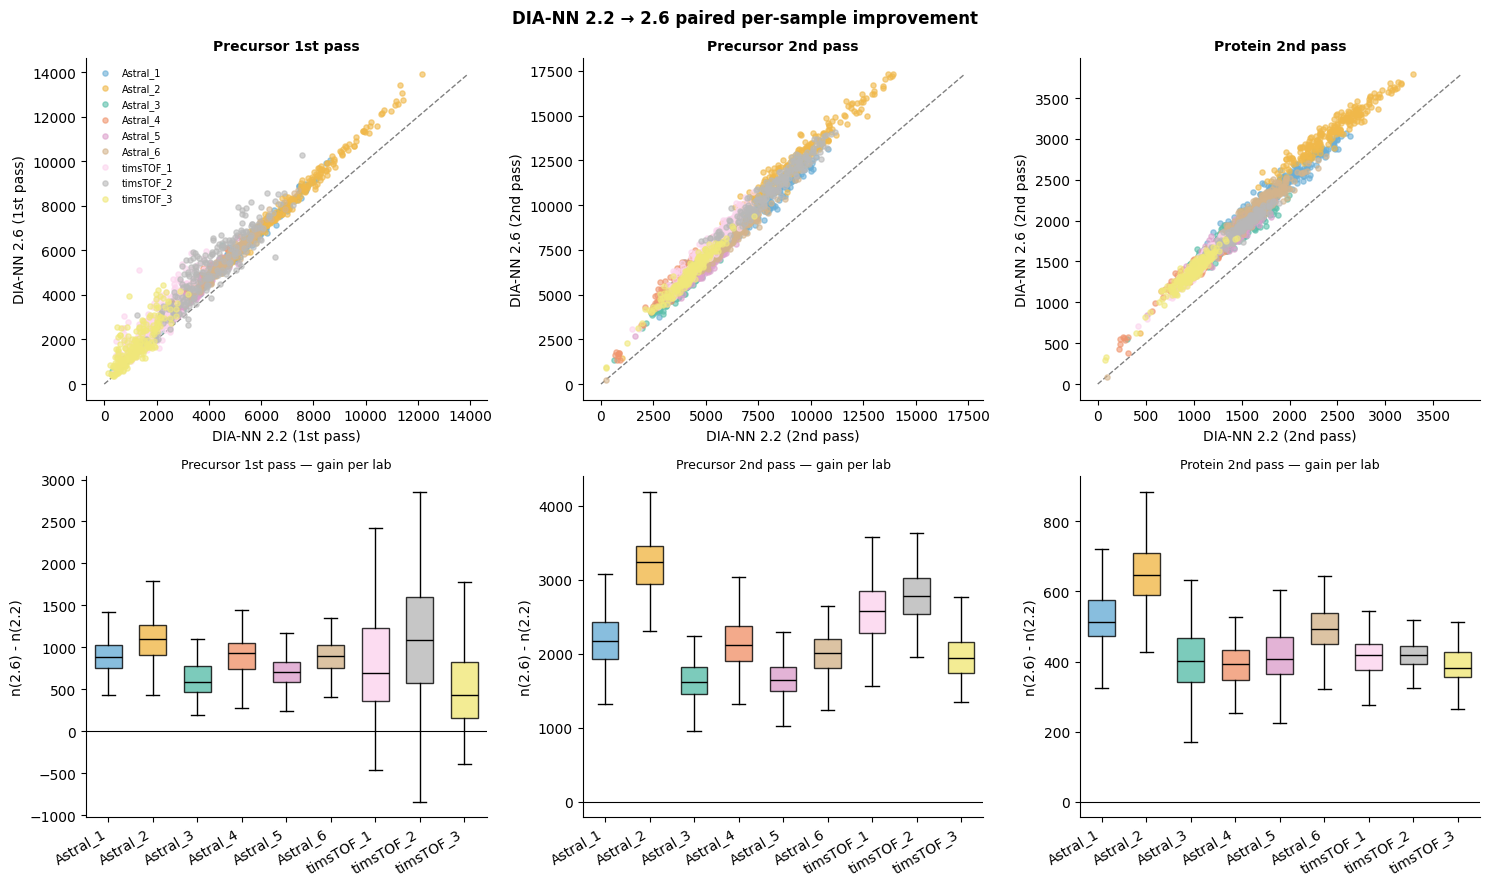

In [7]:
VERSION_PAIRS = [
    ('Precursor 1st pass', 'prec', 'DIA-NN 2.2 (1st pass)', 'DIA-NN 2.6 (1st pass)'),
    ('Precursor 2nd pass', 'prec', 'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)'),
    ('Protein 2nd pass',   'prot', 'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)'),
]

plot_version_improvement(
    VERSION_PAIRS, prec, prot,
    labs=LABS_26, lab_order=LABS_26_ORDER, sc_conditions=SC_CONDITIONS,
    save_dir=SAVE_DIR,
)

### A.4 Feature overlap (2.2 vs 2.6)

Are the precursors found by 2.2 a subset of those found by 2.6, or does each version find
distinct features? The bar chart pools all samples (within 2.6 labs). The histogram shows, per
sample, the fraction of the smaller version's identifications that are also found by the larger
version (coverage of the smaller set).


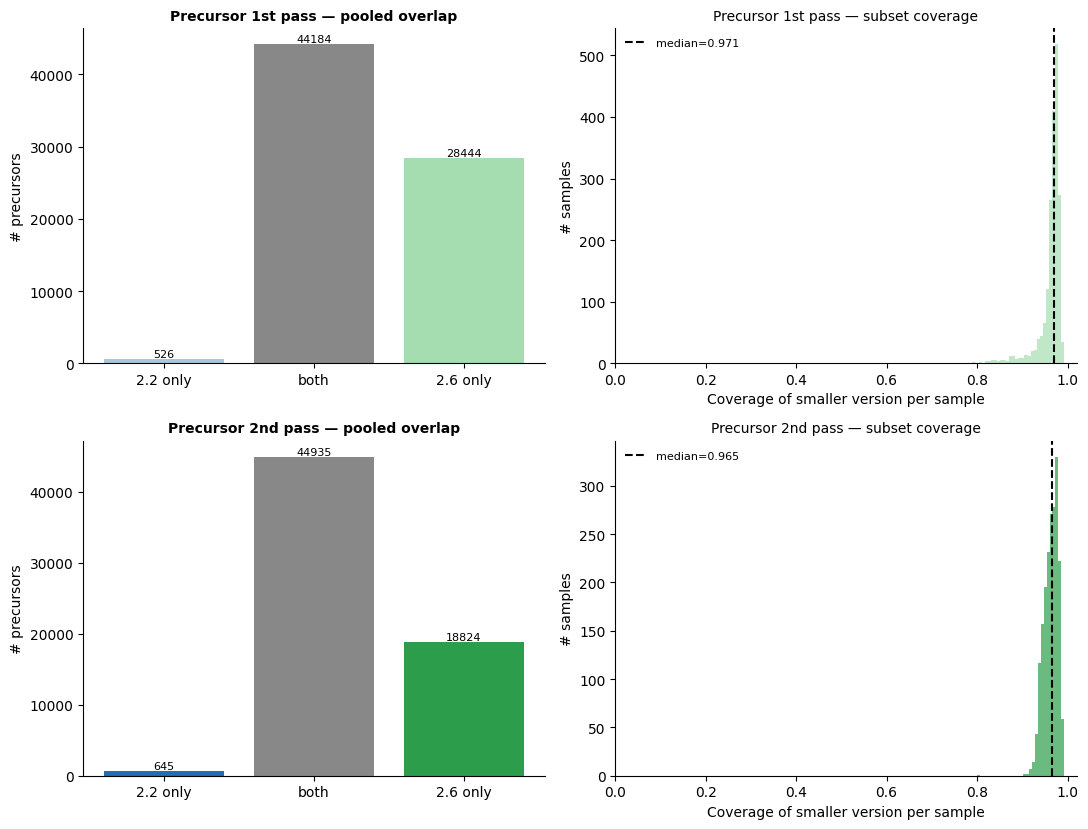

In [8]:
plot_feature_overlap(
    prec,
    pairs=[
        ('Precursor 1st pass', 'DIA-NN 2.2 (1st pass)', 'DIA-NN 2.6 (1st pass)'),
        ('Precursor 2nd pass', 'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)'),
    ],
    level='precursors', feature_level='precursor',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR,
)

### A.5 Quantitative agreement (2.2 vs 2.6)

Per-sample Pearson correlation of log2 intensities on shared features. Because both are DIA-NN
MaxLFQ output, the intensities are directly comparable.


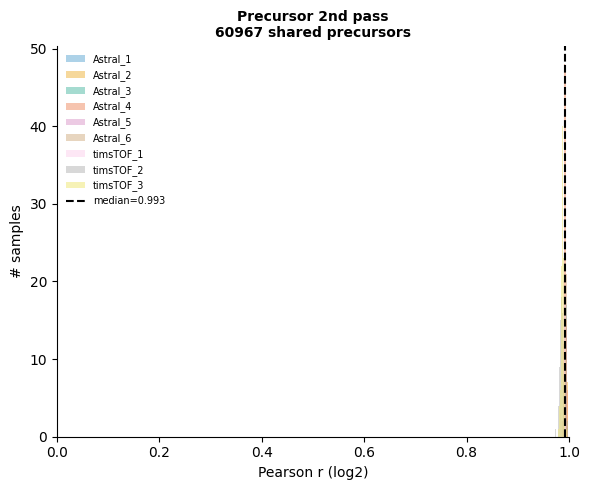

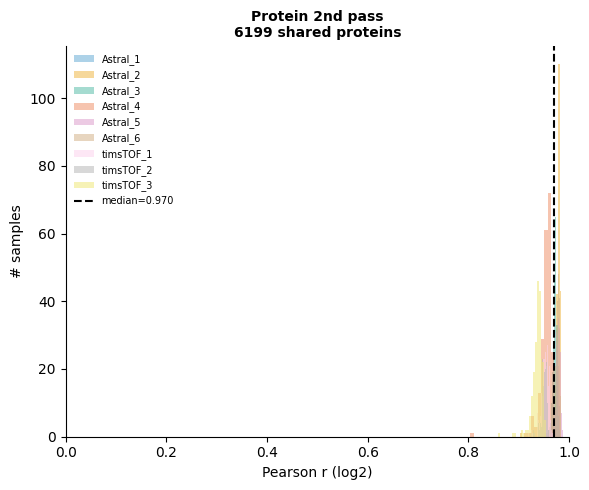

In [9]:
plot_quantitative_correlation(
    prec,
    pairs=[('Precursor 2nd pass', 'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)')],
    level='precursors', feature_level='precursor',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR, filename='A5_correlation_precursor.png',
)

plot_quantitative_correlation(
    prot,
    pairs=[('Protein 2nd pass', 'DIA-NN 2.2 (2nd pass)', 'DIA-NN 2.6 (2nd pass)')],
    level='proteins', feature_level='protein',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR, filename='A5_correlation_protein.png',
)

## Part B — DIA-NN 2.6 vs Spectronaut

DIA-NN 2.6 (2nd pass) is used as the DIA-NN representative. All panels are restricted to the
labs that have 2.6 data and emphasise the lab-by-lab breakdown.

Note on intensities: DIA-NN and Spectronaut report quantities on different absolute scales, so
**CVs are not directly comparable** between the two tools (see Part C). Per-sample correlations
and identification overlap remain meaningful.


### B.1 Identifications lab-by-lab


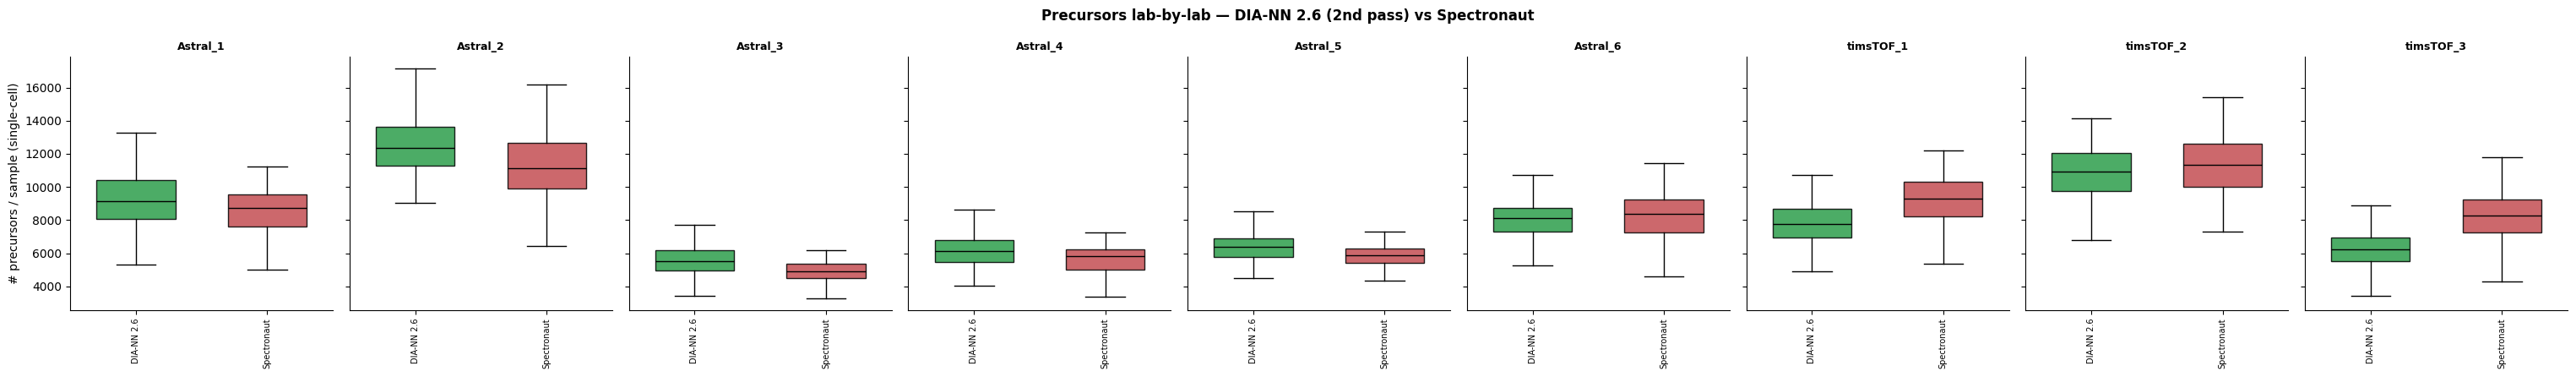

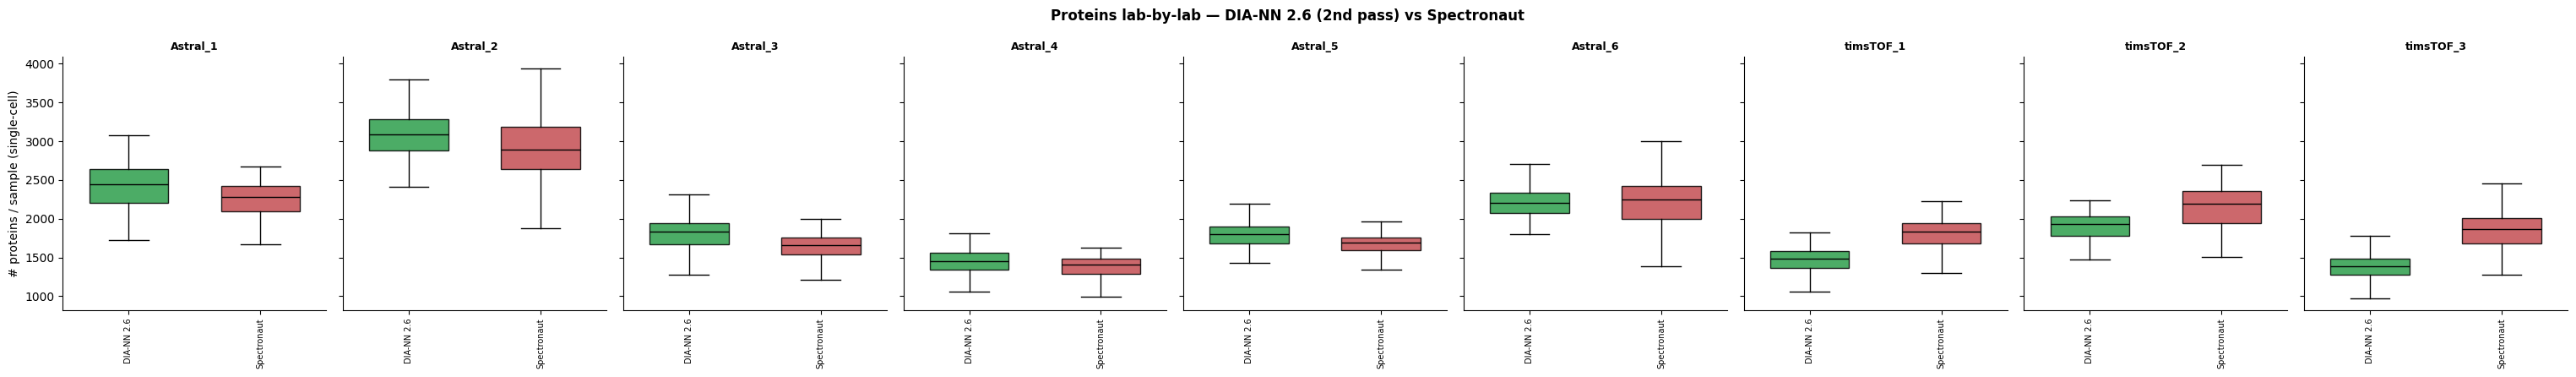

In [10]:
B_PAIR = ['DIA-NN 2.6 (2nd pass)', 'Spectronaut']

plot_tool_counts_per_lab(
    prec, B_PAIR, DATASET_COLORS,
    lab_order=LABS_26_ORDER, labs=LABS_26, sc_conditions=SC_CONDITIONS,
    level='precursors', save_dir=SAVE_DIR,
)

plot_tool_counts_per_lab(
    prot, B_PAIR, DATASET_COLORS,
    lab_order=LABS_26_ORDER, labs=LABS_26, sc_conditions=SC_CONDITIONS,
    level='proteins', save_dir=SAVE_DIR,
)

### B.2 Feature overlap & subset coverage


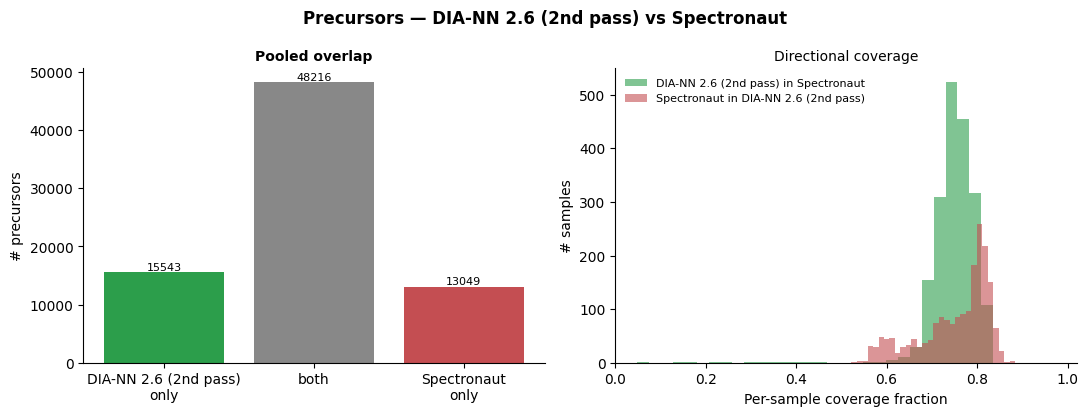

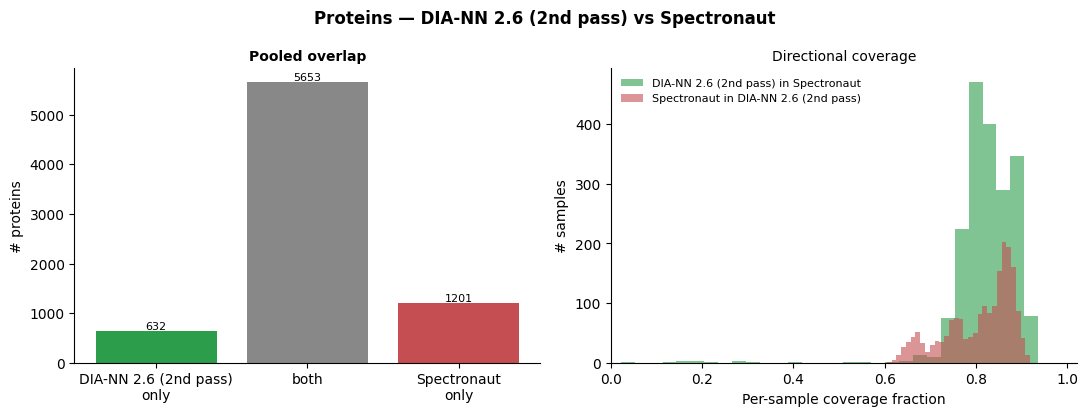

In [11]:
plot_tool_overlap(
    prec, 'DIA-NN 2.6 (2nd pass)', 'Spectronaut',
    level='precursors', feature_level='precursor',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS, save_dir=SAVE_DIR,
)

plot_tool_overlap(
    prot, 'DIA-NN 2.6 (2nd pass)', 'Spectronaut',
    level='proteins', feature_level='protein',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS, save_dir=SAVE_DIR,
)

### B.3 Quantitative agreement


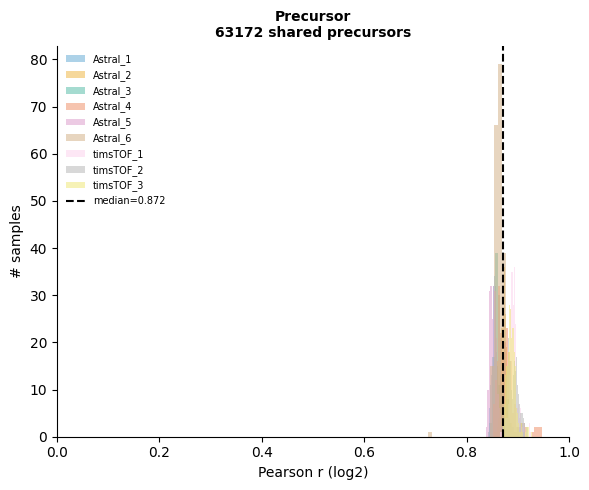

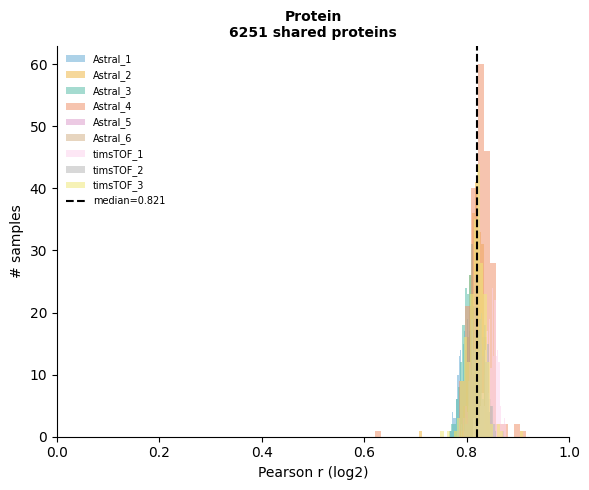

In [12]:
plot_quantitative_correlation(
    prec,
    pairs=[('Precursor', 'DIA-NN 2.6 (2nd pass)', 'Spectronaut')],
    level='precursors', feature_level='precursor',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR, filename='B3_correlation_precursor.png',
)

plot_quantitative_correlation(
    prot,
    pairs=[('Protein', 'DIA-NN 2.6 (2nd pass)', 'Spectronaut')],
    level='proteins', feature_level='protein',
    labs=LABS_26, conditions=SC_CONDITIONS,
    dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR, filename='B3_correlation_protein.png',
)

### B.4 Paired per-sample comparison per lab (DIA-NN 2.6 vs Spectronaut)

Same idea as A.3 but cross-tool and broken out per lab. Each point is one matched sample; the
diagonal marks equal detection (points above it = Spectronaut finds more in that sample). The
delta in each panel title is the median per-sample difference (Spectronaut minus DIA-NN).

The figure is organised into two labelled blocks for the supplementary materials: **(a)**
precursor level and **(b)** protein level. Within each block the nine labs are arranged in a
3×3 grid (the six Astral labs on the top two rows, the three timsTOF labs on the bottom row).
Panels are square with a shared x/y range so the identity diagonal is directly readable.


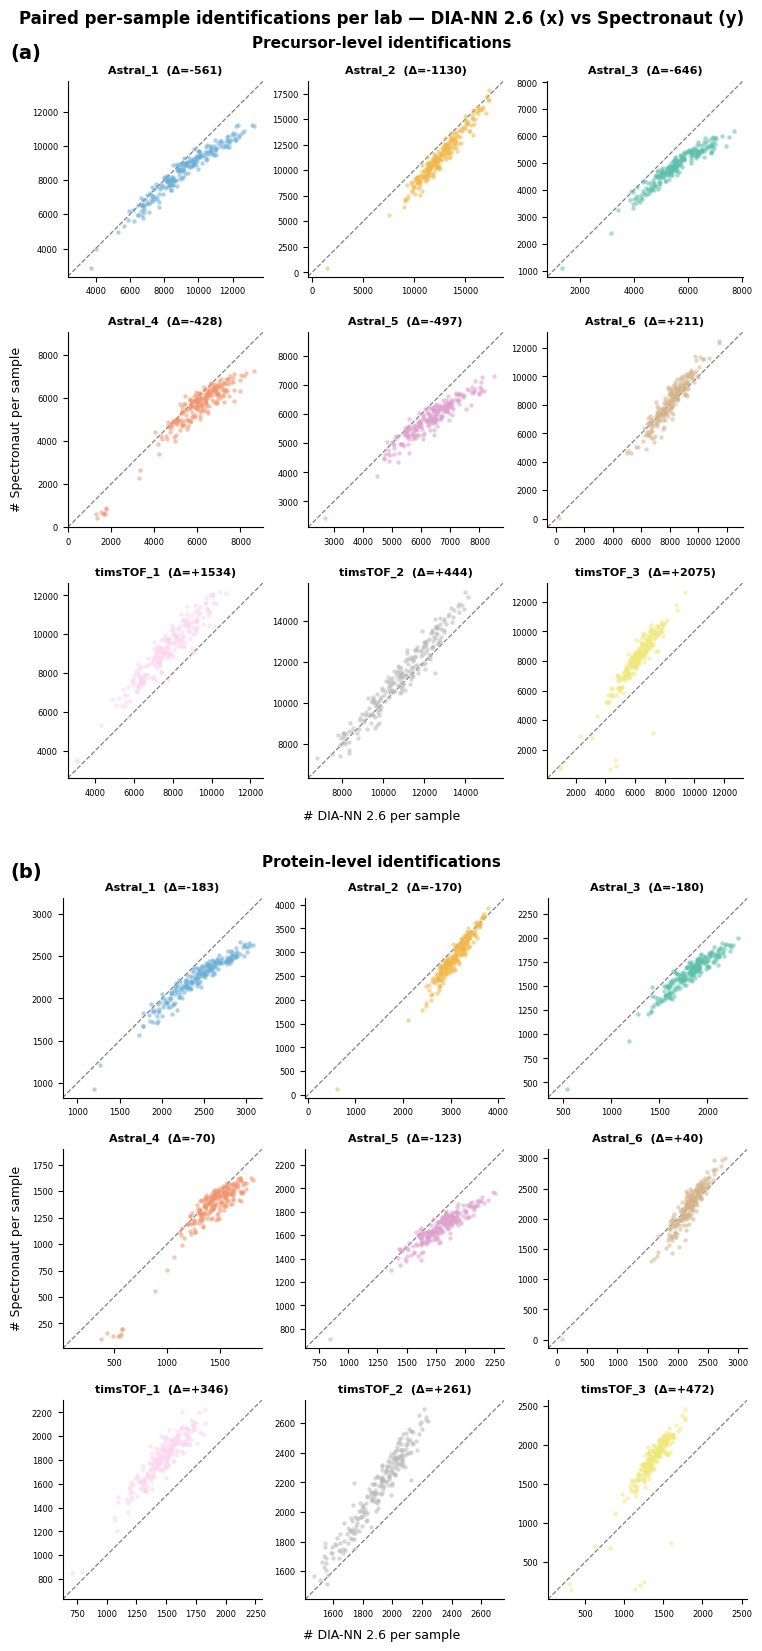

In [13]:
plot_paired_per_lab(
    levels=[('Precursor', prec), ('Protein', prot)],
    name_a='DIA-NN 2.6 (2nd pass)', name_b='Spectronaut',
    lab_order=LABS_26_ORDER, sc_conditions=SC_CONDITIONS,
    save_dir=SAVE_DIR,
)

### B.5 Per-sample precursor overlap decomposition

For each matched sample, the identified precursors are split into three groups: found only by
DIA-NN 2.6, shared, and found only by Spectronaut. A large *only* block on one side means that
tool detects precursors the other misses; if one *only* block is near zero, that tool's
identifications are effectively a subset of the other's.

The first figure shows every sample (stacked bars, faceted by lab). The second summarises the
mean per sample across all samples and per lab, both as counts and as a fraction of the union.


In [14]:
OV_A = 'DIA-NN 2.6 (2nd pass)'
OV_B = 'Spectronaut'

ov = compute_overlap_decomposition(
    prec, OV_A, OV_B,
    lab_order=LABS_26_ORDER, conditions=SC_CONDITIONS,
    feature_level='precursor',
)

print(f'{len(ov)} matched samples across {ov["lab"].nunique()} labs.')
print(f'Median Jaccard (precursor): {ov["jaccard"].median():.3f}')
print(f'Median fraction of {OV_A} that is shared: '
      f'{(ov["shared"] / (ov["only_A"] + ov["shared"])).median() * 100:.1f}%')
print(f'Median fraction of {OV_B} that is shared: '
      f'{(ov["shared"] / (ov["only_B"] + ov["shared"])).median() * 100:.1f}%')

1929 matched samples across 9 labs.
Median Jaccard (precursor): 0.609
Median fraction of DIA-NN 2.6 (2nd pass) that is shared: 75.2%
Median fraction of Spectronaut that is shared: 77.9%


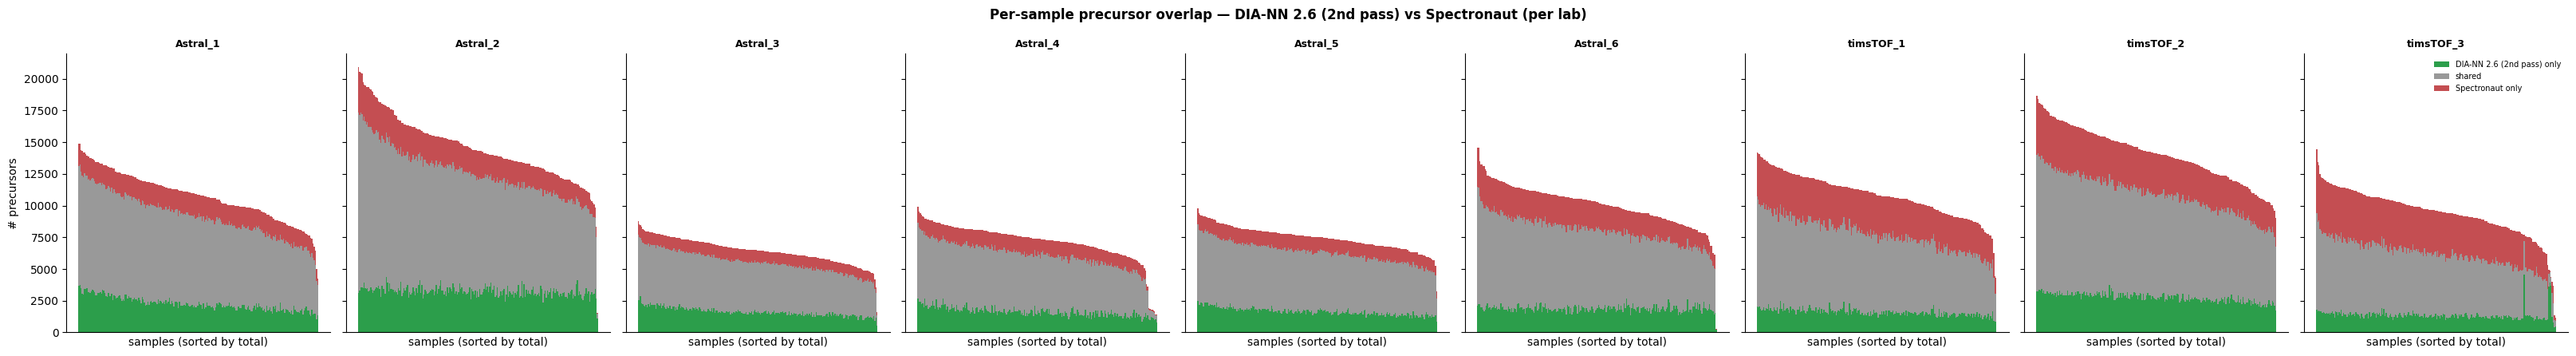

In [15]:
plot_overlap_decomposition_per_lab(
    ov, OV_A, OV_B,
    lab_order=LABS_26_ORDER, dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR,
)

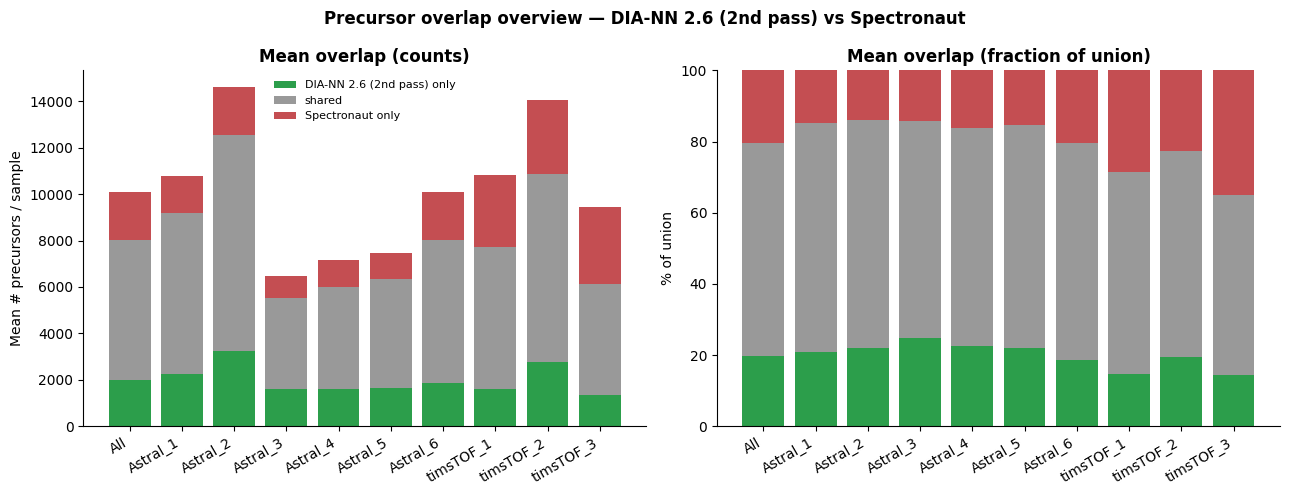

In [16]:
plot_overlap_overview(
    ov, OV_A, OV_B,
    lab_order=LABS_26_ORDER, dataset_colors=DATASET_COLORS,
    save_dir=SAVE_DIR,
)

### B.6 Overlap as a function of abundance rank (DIA-NN 2.6 vs Spectronaut)

How does the overlap between DIA-NN 2.6 and Spectronaut change across the precursor abundance range?

**Approach:** for each matched sample, each tool's detected precursors are ranked by their own intensity (ascending) and divided into equal-frequency bins. Within each bin, the fraction shared with the other tool is computed. Using tool-specific ranks avoids the absolute-scale problem: DIA-NN and Spectronaut report intensities on different scales, so ranking within each tool makes bins conceptually comparable across panels. Bin 1 always represents the lowest-intensity ~10% of *that tool's* detected precursors in *that sample*.

- **Figure B6.1 (boxplot):** each box summarises the % shared across all matched samples for one rank bin and tool. One box = all samples at that abundance level.
- **Figure B6.2 (per-rank profile):** stacked bar for a single example sample and mean ± SD line across all samples, shown separately for each tool's perspective.

In [17]:
N_RANK_BINS = 10

print('Computing precursor binned overlap (may take ~30 s)...')
binned_ov_b6 = compute_binned_overlap(
    prec[OV_A], prec[OV_B], OV_A, OV_B,
    labs=LABS_26_ORDER, conditions=SC_CONDITIONS,
    n_bins=N_RANK_BINS, feature_level='precursor',
)

Computing precursor binned overlap (may take ~30 s)...
1929 matched samples -> 1929 with sufficient features | 38,580 rows
                         count  mean   std  min   25%   50%   75%    max
tool                                                                    
DIA-NN 2.6 (2nd pass)  19290.0  74.8  18.4  0.0  65.1  80.0  89.7   97.9
Spectronaut            19290.0  75.1  15.6  0.0  69.8  80.9  85.8  100.0


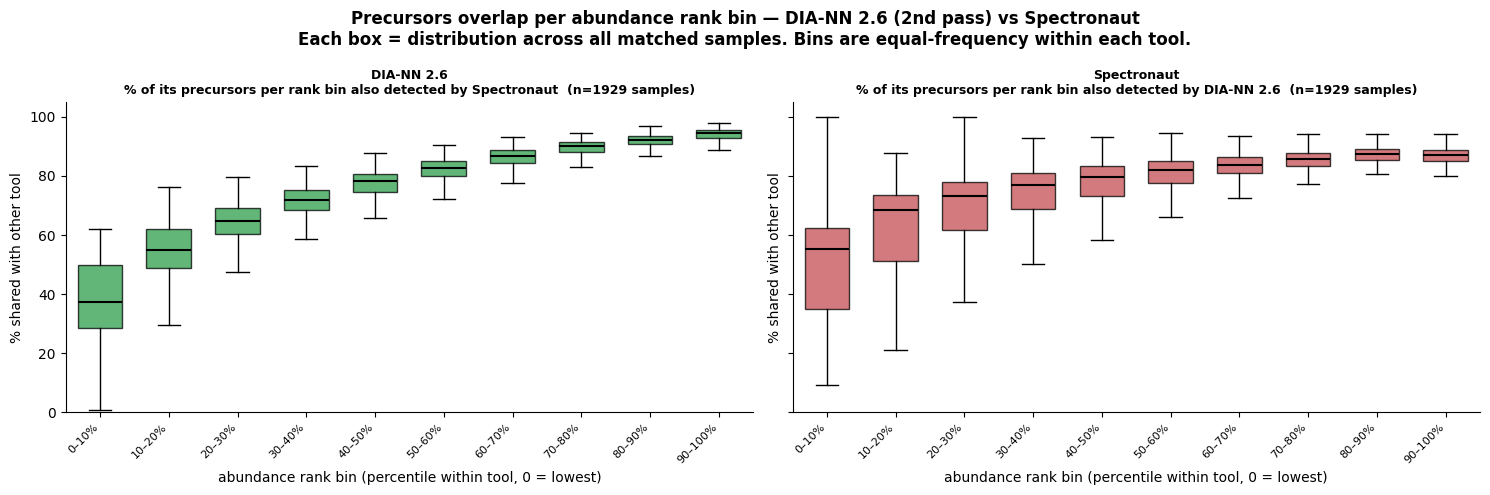

In [18]:
plot_binned_overlap_boxplot(
    binned_ov_b6, OV_A, OV_B, DATASET_COLORS,
    n_bins=N_RANK_BINS, level='precursors',
    save_dir=SAVE_DIR,
)

Example sample: cell_a_c10|DTU_Astral_1


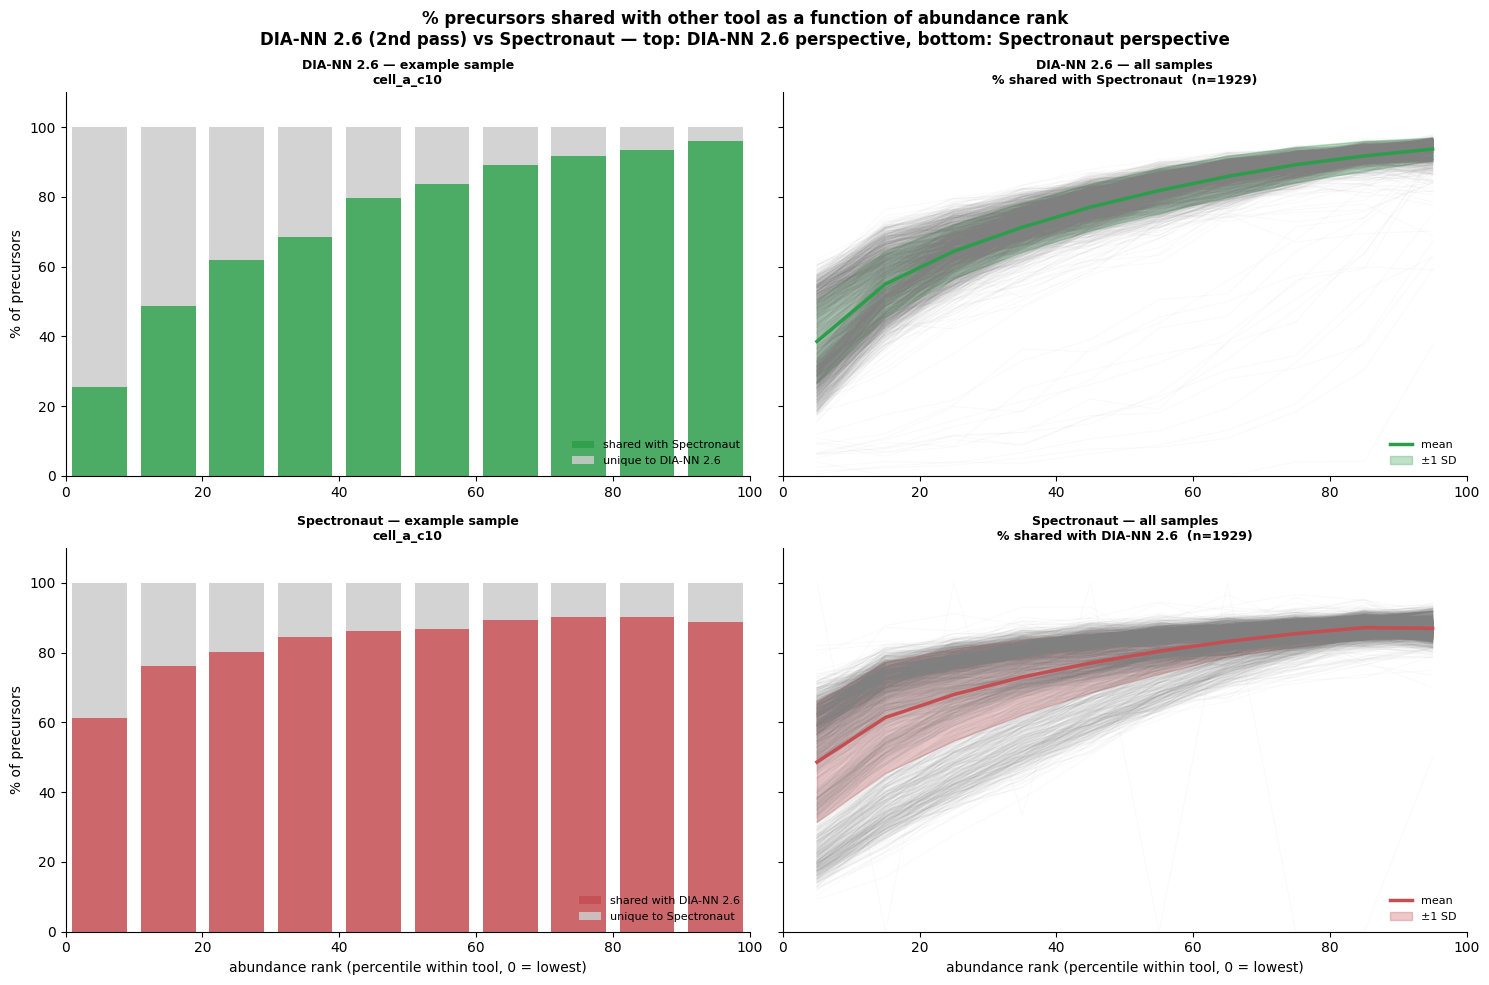

In [19]:
EXAMPLE_SAMPLE_B6 = (binned_ov_b6[binned_ov_b6['lab'] == LABS_26_ORDER[0]]['sample'].iloc[0])
print(f'Example sample: {EXAMPLE_SAMPLE_B6}')

plot_binned_overlap_profile(
    binned_ov_b6, OV_A, OV_B, DATASET_COLORS,
    example_sample=EXAMPLE_SAMPLE_B6,
    n_bins=N_RANK_BINS, level='precursors',
    save_dir=SAVE_DIR,
)

### B.6 (protein level) Overlap as a function of abundance rank

Same analysis as the precursor-level B.6 figures above, repeated at the protein level.
Only 2nd-pass DIA-NN and Spectronaut are used here (1st-pass datasets have no protein
inference). Protein IDs are matched by leading UniProt accession via `_prot_feature_ids`,
so the comparison is robust to Spectronaut's semicolon-delimited `PG.ProteinAccessions` format.

In [20]:
print('Computing protein binned overlap (may take ~15 s)...')
binned_ov_b6_prot = compute_binned_overlap(
    prot[OV_A], prot[OV_B], OV_A, OV_B,
    labs=LABS_26_ORDER, conditions=SC_CONDITIONS,
    n_bins=N_RANK_BINS, feature_level='protein',
)

Computing protein binned overlap (may take ~15 s)...
1929 matched samples -> 1928 with sufficient features | 38,560 rows
                         count  mean   std   min   25%   50%   75%    max
tool                                                                     
DIA-NN 2.6 (2nd pass)  19280.0  82.4  17.1   0.0  77.0  89.4  93.9  100.0
Spectronaut            19280.0  80.8  13.9  15.5  77.2  85.1  89.9  100.0


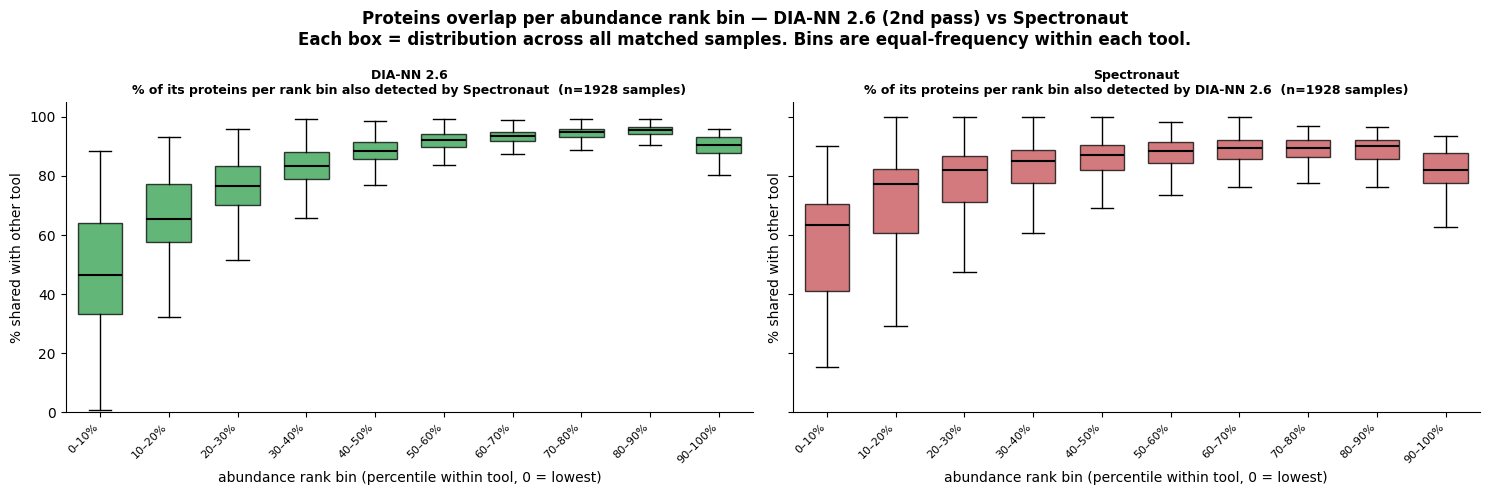

Example sample: cell_a_c10|DTU_Astral_1


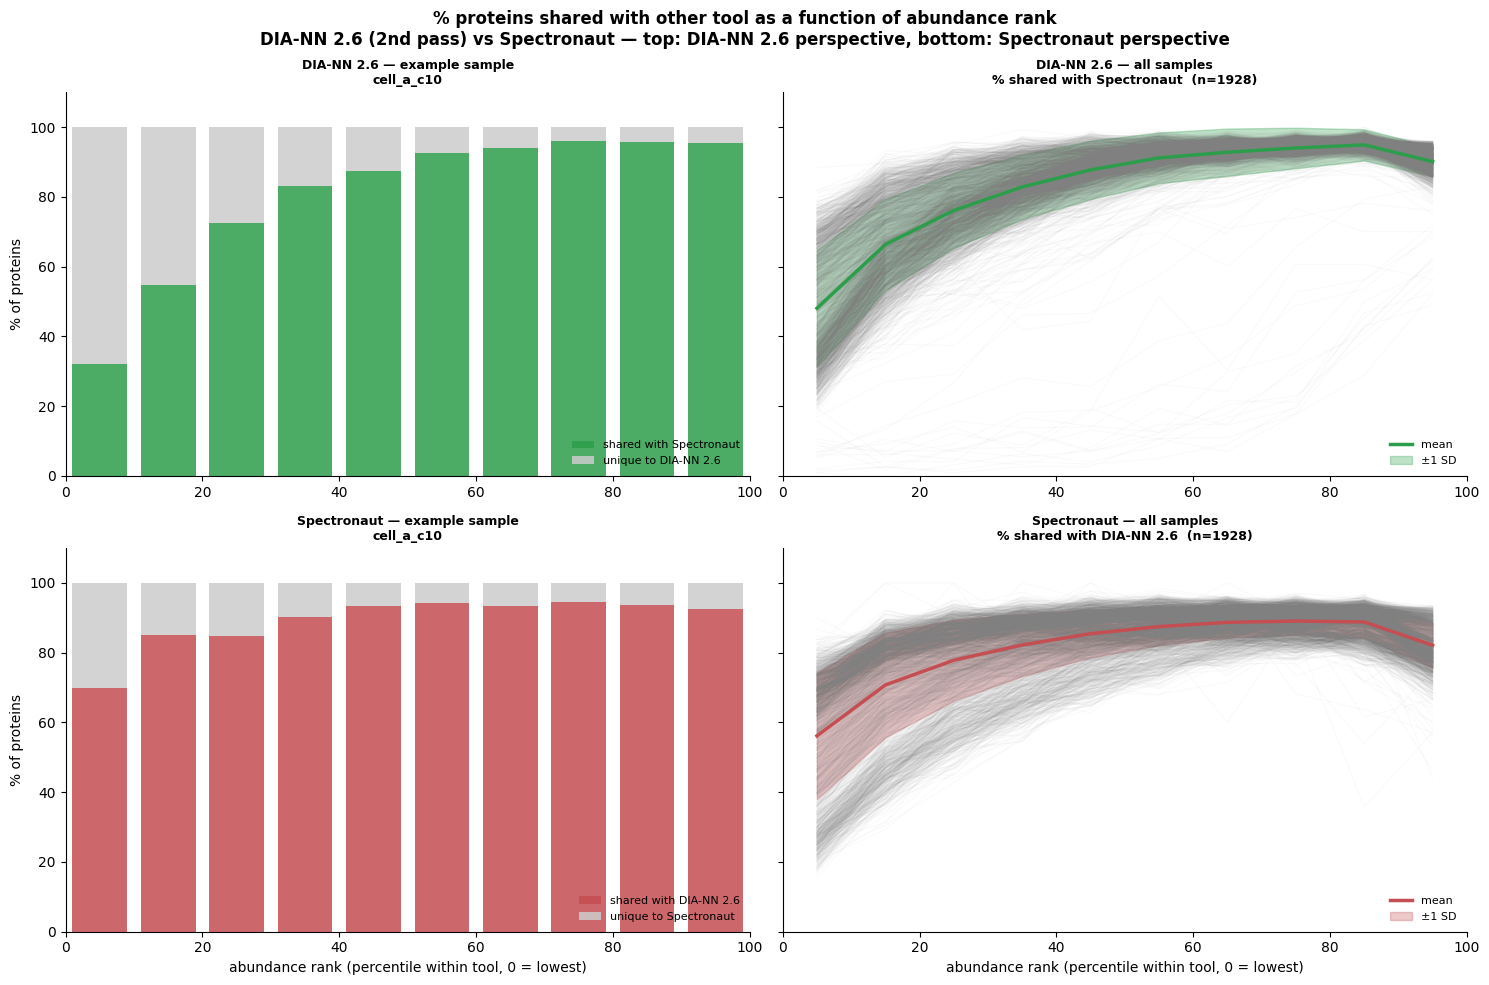

In [21]:
plot_binned_overlap_boxplot(
    binned_ov_b6_prot, OV_A, OV_B, DATASET_COLORS,
    n_bins=N_RANK_BINS, level='proteins',
    save_dir=SAVE_DIR,
)

EXAMPLE_SAMPLE_B6_PROT = (binned_ov_b6_prot[binned_ov_b6_prot['lab'] == LABS_26_ORDER[0]]['sample'].iloc[0])
print(f'Example sample: {EXAMPLE_SAMPLE_B6_PROT}')

plot_binned_overlap_profile(
    binned_ov_b6_prot, OV_A, OV_B, DATASET_COLORS,
    example_sample=EXAMPLE_SAMPLE_B6_PROT,
    n_bins=N_RANK_BINS, level='proteins',
    save_dir=SAVE_DIR,
)

## Part C — Completeness and reproducibility, lab-by-lab

Completeness curves (precursor level, single-cell conditions) per lab, with one line per
dataset. CVs are computed on the linear `.X` matrix per lab and condition.

**Caveat for CV:** CVs are comparable between the two DIA-NN versions (same MaxLFQ units) but
not between DIA-NN and Spectronaut, which report quantities on different scales. The Spectronaut
bars are shown for completeness but should not be read as "more variable".


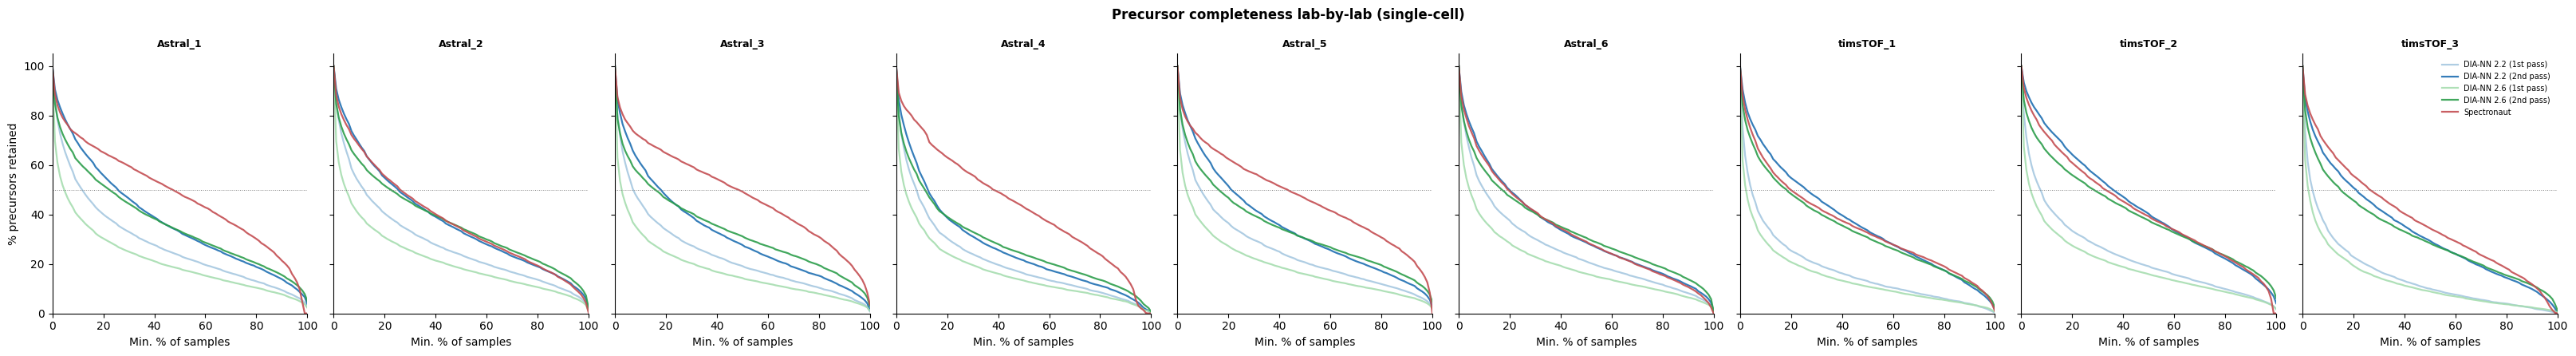

In [22]:
comp = {name: compute_completeness(prec[name], conditions=SC_CONDITIONS, layer='X_log2')
        for name in DATASET_ORDER}

plot_completeness_multi_dataset(
    comp, DATASET_ORDER, DATASET_COLORS,
    lab_order=LABS_26_ORDER,
    save_dir=SAVE_DIR,
)